# Øvingsforelesning 5 - TDT4110

Øving 4: Funksjoner

### Returverdier

print vs return

In [14]:
import math

def find_area(r):
	a = math.pi * r ** 2 
	return a

def print_area(r):
	print(find_area(r))

area = find_area(23)
#1661.90..
print(area)

print_area(23)

1661.9025137490005
1661.9025137490005


#### Oppgave 1
Plot funksjonene $f(x)=x^2$ i intervallet $(-1, 1)$. Velg "oppløsning" på x-aksen selv.

**Ekstraoppgave:** Plot funksjonene $g(x)=x^3$ i samme figur med samme intervall.

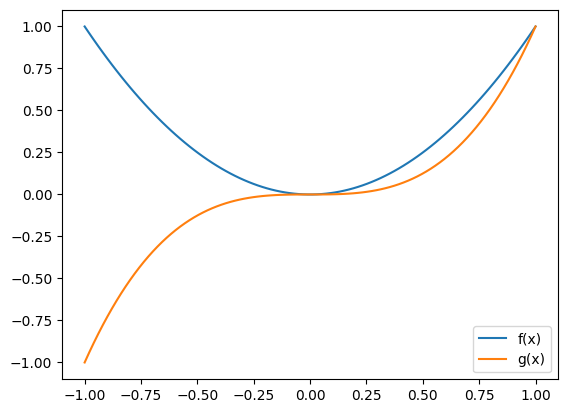

In [45]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
  return x ** 2

def g(x):
  return x** 3

x = np.linspace(-1,1, 100)
y_f = f(x)
y_g = g(x)

plt.plot(x, y_f, label = "f(x)")
plt.plot(x, y_g, label = "g(x)")

plt.legend() # Sørger for at våre labels blir vist
plt.show()

#### Oppgave 2

Plott funksjonene f(x) = sin(2x) og g(x) = cos(2x) i intervallet $(-2 \pi, 2 \pi )$ i hvert sitt plot ved siden av hverandre

Velg "oppløsning" på x-aksen selv.

In [48]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
  return np.sin(2 * x)

def g(x):
  return np.cos(2 * x)

x = np.linspace(-2 * np.pi, 2 * np.pi, 100)
y_f = f(x)
y_g = g(x)

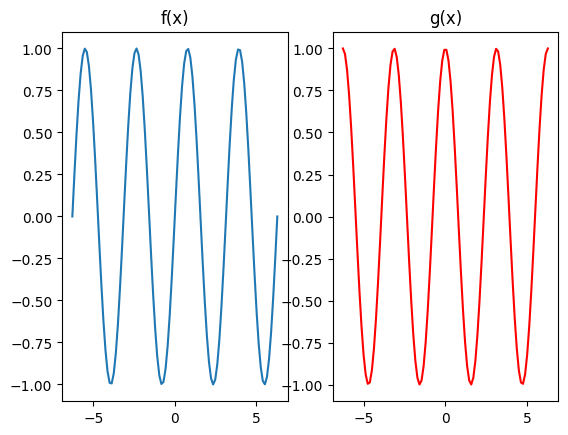

In [34]:
# Pyplot
plt.subplot(1, 2, 1)
plt.title("f(x)")
plt.plot(x, y_f)

plt.subplot(1, 2, 2)
plt.title("g(x)")
plt.plot(x, y_g, color="red")

plt.show()

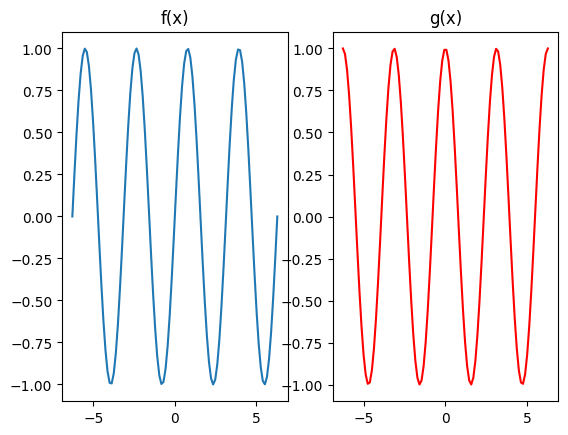

In [36]:
# Object oriented (Som vist i forelesning)
fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.set_title("f(x)")
ax1.plot(x, y_f)

ax2.set_title("g(x)")
ax2.plot(x, y_g, color="red")

plt.show()

#### Oppgave 3

Du vil lage en dum chatbot som svarer ja eller nei med like stor sannsynlighet

Lag en funksjon som tar inn et spørsmål som parameter, og skriver ut spørsmålet og svaret sitt (ja eller nei tilfeldig)

Hint:
```python
import random
random.choice(["Ja", "Nei"])
```

In [49]:
import random

def generate_answer():
    return random.choice(["Ja", "Nei"])

def ask_question(question):
    print(f"Spm: {question}")
    print(f"Svar: {generate_answer()}")

#for i in range(10):
#    print(generate_answer())
question = input("Skriv inn et spørsmål: ")
ask_question(question)

Spm: Er du smart?
Svar: Ja


#### Oppgave 4

Vi ønsker å regne ut fakultet (factorial) av noen tall, og skal derfor lage en funksjon som implementerer denne logikken.

For eksempel er 4! = 1⋅2⋅3⋅4 = 24, mens 5! = 1⋅2⋅3⋅4⋅5 = 120.

In [17]:
def factorial(n):
    result = 1

    for i in range(2, n + 1):
        result *= i

    return result

print(factorial(4))
print(factorial(5))

24
120


#### Oppgave 5

Lag en funksjon som tar inn en streng, og returnerer antall små og antall store bokstaver i strengen. Benytt funksjonene str#isupper() og str#islower().

In [18]:
def count_lower_upper(s):
    lower = 0
    upper = 0

    for ch in s:
        if ch.islower():
            lower += 1
        elif ch.isupper():
            upper += 1
    
    return lower, upper

count_lower, count_upper = count_lower_upper("Hei")
print(f"Lower: {count_lower}")
print(f"Upper: {count_upper}")

Lower: 2
Upper: 1


#### Eksempel - Lokale og Globale variabler

In [ ]:
def foo():
  x = 5
  print("Inne i funksjonen: ",x)


x = 0
print("Før funksjonen har kjørt:", x)
foo()
print("Etter funksjonen har kjørt:",x)

#### Oppgave 6

Forsikring av input-type

Lag en funksjon som spør bruker om et heltall, og spør igjen dersom brukeren ikke skriver inn et heltall.
Når brukeren har skrevet inn et heltall, skal funksjonen returnere tallet 

Hint: 
str.isnumeric() sjekker om en streng kun inneholder tall 

In [2]:
def input_int(prompt = "Skriv inn et tall: "):
    while True:
        given = input(prompt)

        if given.isnumeric():
            return int(given)
        
        print(f"'{given}' er ikke et gyldig tall!")

tall = input_int()
print(tall)

'hei' er ikke et gyldig tall!
'5.0.0' er ikke et gyldig tall!
5


#### Oppgave 7

Primtallstester

Skriv en funksjon som tar inn et heltall, og returnerer True hvis tallet er et primtall, ellers False

Husk: Et tall er et primtall hvis det ikke er delelig på noen andre tall enn seg selv og 1. De første primtallene er 2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37.

In [6]:
# Inneholder 3 ulike versjoner av ulik kompleksitet, hvor de mer kompliserte
# er teoretisk raskere

# Bruker math-modul i versjon3
import math

# Versjon 1; Denne er den mest "grunnleggende", og sjekker bare om 
# n går opp i alle tall mellom 2 og n - 1
def is_prime1(n):
    if n == 0 or n == 1:
        return False

    for i in range(2, n):
        if n % i == 0:
            return False
        
    return True

# Versjon 2; Fra forelesning. Håndterer partall eksplisitt, og sjekk
# alle oddetall fra 3 til n - 1
def is_prime2(n):
    if n == 1:
        return False
    
    if n != 2 and n % 2 == 0:
        return False
    
    for i in range(3, n, 2):
        if n % i == 0:
            return False
        
    return True

# Versjon 3: Samme som i forelesning, men sjekker bare alle tall opp 
# til kvadratroten av tallet. Dette funker fordi for å faktorisere n må 
# vi minst ha 1 faktor som er mindre enn kvadratroten av tallet
def is_prime3(n):
    if n == 1:
        return False
    
    if n != 2 and n % 2 == 0:
        return False
    
    # Vi ønsker å runde opp her for å sikre at vi får med alle relevante tall
    lim = math.ceil(math.sqrt(n))

    for i in range(3, lim + 1, 2):
        if n % i == 0:
            return False
        
    return True

for i in range(1, 21):
    print(f"{i}: {is_prime1(i)} - {is_prime2(i)} - {is_prime3(i)}")

1: False - False - False
2: True - True - True
3: True - True - True
4: False - False - False
5: True - True - True
6: False - False - False
7: True - True - True
8: False - False - False
9: False - False - False
10: False - False - False
11: True - True - True
12: False - False - False
13: True - True - True
14: False - False - False
15: False - False - False
16: False - False - False
17: True - True - True
18: False - False - False
19: True - True - True
20: False - False - False


#### Oppgave 8 (1/2)

Lag en funksjon `beregn_omkrets` som gjør følgende:
 - Tar inn et tall radius som parameter
 - Returnerer omkretsen til en sirkel med radius <radius>

Lag en funksjon `beregn_areal` som gjør følgende:
 - Tar inn et tall radius som parameter
 - Returnerer arealet til en sirkel med radius <radius>

In [22]:
import math

def beregn_omkrets(radius):
    return 2 * math.pi * radius

def beregn_areal(radius):
    return math.pi * radius ** 2

#### Oppgave 8 (2/2)

Lag en `geometriprogram()`-funksjon som gjør følgende:
 - Spør om radius fra en bruker med `input()`
 - Regner ut omkretsen av en sirkel med radius <radius>
 - Regner ut arealet av en sirkel med radius <radius>
 - Skriver ut resultatet fra del (2) og (3)

In [23]:
def geometriprogram():
    radius = input_int("Skriv inn en radius: ")

    omkrets = beregn_omkrets(radius)
    areal = beregn_areal(radius)

    print(f"Omkrets: {omkrets}")
    print(f"Areal: {areal}")

geometriprogram()

Omkrets: 62.83185307179586
Areal: 314.1592653589793


#### Oppgave 9 (1/3)

Vi skal lage et enkelt terningspill. I spillet trenger vi mulighet til å trille en terning

Lag en funksjon som triller en terning, dvs. returnerer et tall fra og med 1 til og med 6

Hint: 
```python
import random

x = random.randint(1, 6) 
```

In [24]:
import random

def roll_dice():
    return random.randint(1, 6)

for i in range(10):
    print(roll_dice())

6
3
2
4
3
1
6
5
1
3


#### Oppgave 9 (2/3)

En runde i spillet består av at spilleren gjetter hvor mye hen til sammen kommer til å trille, før 6 terninger trilles. Hvis hen gjettet riktig, får hen 3 poeng. Hvis hen var innenfor 5 fra riktig verdi, får hen 1 poeng. 

Lag en funksjon for å beregne poeng gitt spilleren, basert på spillerens gjett og verdien til de trillede terningene. 

Lag så en funksjon for en runde, som spør spilleren om å gjette, triller terninger, og returnerer poengsummen for den runden. 

In [27]:
def get_points(actual, guess):
    if actual == guess:
        return 3
    elif abs(actual - guess) <= 5:
        return 1
    else:
        return 0


def play_round():
    guess = input_int("Hvor mye kommer du til å trille? ")

    actual = 0

    for i in range(6):
        roll = roll_dice()
        actual += roll
        print(f"Du trillet {roll}")

    print(f"Du fikk totalt {actual}")
    score = get_points(actual, guess)
    print(f"Du fikk {score} poeng!")
    return score

poeng = play_round()

Du trillet 2
Du trillet 4
Du trillet 1
Du trillet 6
Du trillet 6
Du trillet 3
Du fikk totalt 22
Du fikk 3 poeng!


#### Oppgave 9 (3/3)

Til slutt vil vi ha mulighet til å spille hele spillet

Husk: `main()` kaller de andre funksjonene og står for kommunikasjon med bruker

Spør spilleren først hvor mange runder hen vil spille, og kjør så gjennom <antall> mange runder. Hold kontroll på poengsummen til brukeren, og skriv den ut til slutt. 

Ekstraoppgave:
Utvid spillet til å være for to spillere

In [26]:
def main():
    rounds = input_int("Hvor mange runder vil du spille? ")

    total_score = 0

    for i in range(rounds):
        total_score += play_round()

    print(f"Du fikk totalt {total_score} poeng!")

main()

Du trillet 6
Du trillet 2
Du trillet 2
Du trillet 4
Du trillet 6
Du trillet 2
Du fikk totalt 22
Du fikk 3 poeng!
Du trillet 5
Du trillet 2
Du trillet 6
Du trillet 5
Du trillet 4
Du trillet 1
Du fikk totalt 23
Du fikk 1 poeng!
Du fikk totalt 4 poeng!
